# Section 10. ELS 가격평가와 헤징

**상경계를 위한 Python 입문 · 실행 결과가 포함된 실습 노트북**

강의록 `section10_els_pricing_hedging.tex`의 모든 코드 예제를 순서대로 수록했습니다. 이 파일은 앞 장의 노트북을 실행하지 않아도 처음부터 실행할 수 있습니다. **커널 다시 시작 → 모두 실행**으로 확인하세요.

이 노트북에서는 두 자산 Monte Carlo 예제를 먼저 계산하고, 뒤에서 강의록의 **별도 1자산 FDM·일별 헤지 예제**를 재현합니다. 두 상품의 가격을 직접 비교하지 않습니다. 모든 난수시드와 본문 계산규모는 강의록과 같습니다.

학습 순서: **상품조건 → 경로와 상태 → 가격과 상환확률 → Greeks → 자기금융 헤지 → FDM 상태별 가격곡선**.

## 1. 상품조건을 상태변수로 표현하기

두 자산의 기준가격 대비 성과 중 작은 값을 사용합니다.

$$W_t=\min\{S_t^{(1)}/S_0^{(1)},\ S_t^{(2)}/S_0^{(2)}\}.$$

| 항목 | 이번 두 자산 예제 |
|---|---|
| 원금 / 기준가격 | 100 / 각 자산 100 |
| 만기 / 관찰간격 | 3년 / 0.5년 |
| 상환기준 | 90%, 90%, 85%, 85%, 80%, 80% |
| 쿠폰 / knock-in | 연 8% 단리 / 60% |
| 금리 / 배당률 | 3% / 1%, 1.5% |
| 변동성 / 상관계수 | 20%, 25% / 0.50 |

상환기준을 처음 만족한 관찰일에 $100(1+0.08t)$를 지급합니다. 만기까지 상환기준을 만족하지 못했더라도 knock-in이 없으면 같은 만기 쿠폰을 지급하고, knock-in이 발생했으면 $100W_T$를 지급합니다.

경로마다 `alive`, `knocked_in`, 지급액, 지급시점을 기록하면 전체 과거 경로를 보관하지 않고 계산할 수 있습니다. 이 구현은 **simulation grid에서 knock-in을 검사**합니다. 3년을 360단계로 나누므로 매일 종가 감시 또는 연속 감시와는 관찰규칙이 다릅니다.

**이번 장에서 사용할 라이브러리 불러오기**  
강의록 Listing 1 · `section10_els_pricing_hedging.tex` 224행

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

**교육용 ELS 상품조건과 시장입력**  
강의록 Listing 2 · `section10_els_pricing_hedging.tex` 233행

In [2]:
terms = {
    "notional": 100.0,
    "reference_spots": np.array([100.0, 100.0], dtype=float),
    "observation_times": np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0], dtype=float),
    "redemption_barriers": np.array([0.90, 0.90, 0.85, 0.85, 0.80, 0.80], dtype=float),
    "coupon_rate": 0.08,
    "knock_in_barrier": 0.60,
}

market = {
    "spots": np.array([100.0, 100.0], dtype=float),
    "rate": 0.03,
    "dividend_yields": np.array([0.01, 0.015], dtype=float),
    "volatilities": np.array([0.20, 0.25], dtype=float),
    "correlation": 0.50,
}

In [3]:
pd.DataFrame({
    "관찰일(년)": terms["observation_times"],
    "상환기준": terms["redemption_barriers"],
    "조건 충족 시 지급액": terms["notional"] * (1.0 + terms["coupon_rate"] * terms["observation_times"]),
})

,관찰일(년),상환기준,조건 충족 시 지급액
0,0.5,0.90,104.0
1,1.0,0.90,108.0
2,1.5,0.85,112.0
3,2.0,0.85,116.0
4,2.5,0.80,120.0
5,3.0,0.80,124.0


## 2. 상관된 주가경로와 ELS 가격함수

위험중립측도 $\mathbb{Q}$ 아래에서 두 자산을 Euler–Maruyama 방식으로 생성합니다. 두 번째 충격을 $\rho Z_1+\sqrt{1-\rho^2}Z_2$로 만들고, 생존 경로에서 knock-in과 최초 상환 여부를 갱신합니다.

**읽는 순서:** 입력 검증 → 관찰일을 격자에 대응 → 경로별 상태 초기화 → 경로 생성과 상태 갱신 → 만기 현금흐름 → 경로별 할인과 표준오차. 함수 정의 셀은 결과를 출력하지 않습니다. 다음 절에서 함수를 호출합니다.

**두 자산 step-down ELS Monte Carlo 가격함수**  
강의록 Listing 3 · `section10_els_pricing_hedging.tex` 300행

In [4]:
def price_stepdown_els(terms, market, n_paths, n_steps, seed):
    notional = float(terms["notional"])
    reference_spots = np.asarray(terms["reference_spots"], dtype=float)
    observation_times = np.asarray(terms["observation_times"], dtype=float)
    barriers = np.asarray(terms["redemption_barriers"], dtype=float)
    coupon_rate = float(terms["coupon_rate"])
    knock_in_barrier = float(terms["knock_in_barrier"])

    spots0 = np.asarray(market["spots"], dtype=float)
    dividend_yields = np.asarray(market["dividend_yields"], dtype=float)
    volatilities = np.asarray(market["volatilities"], dtype=float)
    rate = float(market["rate"])
    correlation = float(market["correlation"])

    counts = (("n_paths", n_paths, 2), ("n_steps", n_steps, 1), ("seed", seed, 0))
    for name, value, minimum in counts:
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_paths = int(n_paths)
    n_steps = int(n_steps)
    seed = int(seed)
    if observation_times.ndim != 1 or observation_times.size == 0:
        raise ValueError("observation_times must be a nonempty 1D array")
    if barriers.shape != observation_times.shape:
        raise ValueError("barriers must match observation_times")
    arrays = (reference_spots, spots0, observation_times, barriers, dividend_yields, volatilities)
    if not all(np.isfinite(values).all() for values in arrays):
        raise ValueError("market and contract arrays must be finite")
    scalars = [notional, coupon_rate, knock_in_barrier, rate, correlation]
    if not np.isfinite(scalars).all():
        raise ValueError("market and contract parameters must be finite")
    if notional <= 0.0 or np.any(reference_spots <= 0.0) or np.any(spots0 <= 0.0):
        raise ValueError("notional and spot prices must be positive")
    if observation_times[0] <= 0.0 or np.any(volatilities < 0.0):
        raise ValueError("require positive dates and nonnegative volatility")
    if not 0.0 < knock_in_barrier < np.min(barriers):
        raise ValueError("this example requires 0 < KI < redemption barriers")
    maturity = float(observation_times[-1])

    if reference_spots.shape != (2,) or spots0.shape != (2,):
        raise ValueError("This educational function requires two underlyings")
    if dividend_yields.shape != (2,) or volatilities.shape != (2,):
        raise ValueError("Market arrays must have length 2")
    if observation_times.size != barriers.size:
        raise ValueError("Observation times and barriers must have equal length")
    if np.any(np.diff(observation_times) <= 0.0):
        raise ValueError("Observation times must be increasing")
    if not (-1.0 < correlation < 1.0):
        raise ValueError("Correlation must lie between -1 and 1")

    dt = maturity / n_steps
    sqrt_dt = np.sqrt(dt)
    observation_steps = np.rint(observation_times / dt).astype(int)

    if not np.allclose(observation_steps * dt, observation_times, rtol=0.0, atol=1.0e-10):
        raise ValueError("Observation dates must lie on the time grid")
    if observation_steps[0] < 1 or np.any(np.diff(observation_steps) <= 0):
        raise ValueError("Observation dates must map to distinct positive steps")

    rng = np.random.default_rng(seed)
    stocks = np.repeat(spots0[:, None], n_paths, axis=1)
    alive = np.ones(n_paths, dtype=bool)
    initial_ki = np.min(spots0 / reference_spots) <= knock_in_barrier
    knocked_in = np.full(n_paths, initial_ki, dtype=bool)
    cashflow = np.zeros(n_paths, dtype=float)
    payment_time = np.full(n_paths, maturity, dtype=float)
    redemption_index = np.full(n_paths, -1, dtype=int)

    obs_lookup = {step: index for index, step in enumerate(observation_steps)}
    correlation_scale = np.sqrt(1.0 - correlation**2)

    for step in range(1, n_steps + 1):
        z1 = rng.standard_normal(n_paths)
        z2_independent = rng.standard_normal(n_paths)
        z2 = correlation * z1 + correlation_scale * z2_independent
        shocks = np.vstack((z1, z2))

        drift = (rate - dividend_yields[:, None]) * stocks * dt
        diffusion = volatilities[:, None] * stocks * sqrt_dt * shocks
        stocks = stocks + drift + diffusion

        if np.any(stocks <= 0.0):
            raise RuntimeError("Euler scheme produced a nonpositive stock price")

        performance = stocks / reference_spots[:, None]
        worst_performance = np.min(performance, axis=0)
        knocked_in[alive] |= worst_performance[alive] <= knock_in_barrier

        if step in obs_lookup:
            index = obs_lookup[step]
            redeemed = alive & (worst_performance >= barriers[index])
            cashflow[redeemed] = notional * (1.0 + coupon_rate * observation_times[index])
            payment_time[redeemed] = observation_times[index]
            redemption_index[redeemed] = index
            alive[redeemed] = False

    final_worst = np.min(stocks / reference_spots[:, None], axis=0)
    no_knock_in = alive & (~knocked_in)
    loss_redemption = alive & knocked_in

    cashflow[no_knock_in] = notional * (1.0 + coupon_rate * maturity)
    cashflow[loss_redemption] = notional * final_worst[loss_redemption]

    discounted_cashflow = cashflow * np.exp(-rate * payment_time)
    price = float(discounted_cashflow.mean())
    standard_error = float(discounted_cashflow.std(ddof=1) / np.sqrt(n_paths))

    probabilities = np.array(
        [np.mean(redemption_index == i) for i in range(observation_times.size)],
        dtype=float,
    )
    payment_probabilities = probabilities.copy()
    payment_probabilities[-1] += np.mean(redemption_index == -1)

    return {
        "price": price,
        "standard_error": standard_error,
        "redemption_probabilities": probabilities,
        "payment_probabilities": payment_probabilities,
        "maturity_probability": float(payment_probabilities[-1]),
        "knock_in_probability": float(np.mean(knocked_in)),
        "loss_probability": float(np.mean(cashflow < notional)),
        "average_payment_time": float(payment_time.mean()),
    }

## 3. 가격, 상환시점과 진단통계

본문과 동일하게 **30,000경로, 360단계, seed 2026**을 사용합니다. 각 경로의 현금흐름을 실제 지급시점으로 할인합니다.

**ELS 가격과 주요 진단통계 계산하기**  
강의록 Listing 4 · `section10_els_pricing_hedging.tex` 431행

In [5]:
result = price_stepdown_els(
    terms=terms,
    market=market,
    n_paths=30_000,
    n_steps=360,
    seed=2026,
)

for key, value in result.items():
    if np.ndim(value) == 0:
        print(f"{key}: {value:.6f}")

price: 96.093392
standard_error: 0.114477
maturity_probability: 0.177500
knock_in_probability: 0.168133
loss_probability: 0.145967
average_payment_time: 1.162617


**강의록에 제시된 참고 출력 · Listing 5**  
아래 블록은 강의록의 원문입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에 저장되어 있습니다.

```text
price: 96.093392
standard_error: 0.114477
maturity_probability: 0.177500
knock_in_probability: 0.168133
loss_probability: 0.145967
average_payment_time: 1.162617
```

가격 외에 표준오차, 만기까지 생존할 확률, knock-in 확률, 원금손실 확률과 평균상환기간을 함께 확인합니다. 아래 확률은 모두 이 모형의 **위험중립측도 $\mathbb{Q}$ 아래의 발행시점 기준 무조건부 확률**입니다. 실제 투자손실을 예측하는 물리적 측도 $\mathbb{P}$의 확률과는 구분합니다.

**상환시점별 위험중립확률**  
강의록 Listing 6 · `section10_els_pricing_hedging.tex` 471행

In [6]:
redemption_table = pd.DataFrame({
    "time": terms["observation_times"],
    "probability": result["payment_probabilities"],
})
print(redemption_table)
assert np.isclose(redemption_table["probability"].sum(), 1.0)

   time  probability
0   0.5     0.605067
1   1.0     0.090000
2   1.5     0.066933
3   2.0     0.028133
4   2.5     0.032367
5   3.0     0.177500


**강의록에 제시된 참고 출력 · Listing 7**  
아래 블록은 강의록의 원문입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에 저장되어 있습니다.

```text
   time  probability
0   0.5     0.605067
1   1.0     0.090000
2   1.5     0.066933
3   2.0     0.028133
4   2.5     0.032367
5   3.0     0.177500
```

**상환시점별 확률 막대그래프**  
강의록 Listing 8 · `section10_els_pricing_hedging.tex` 492행

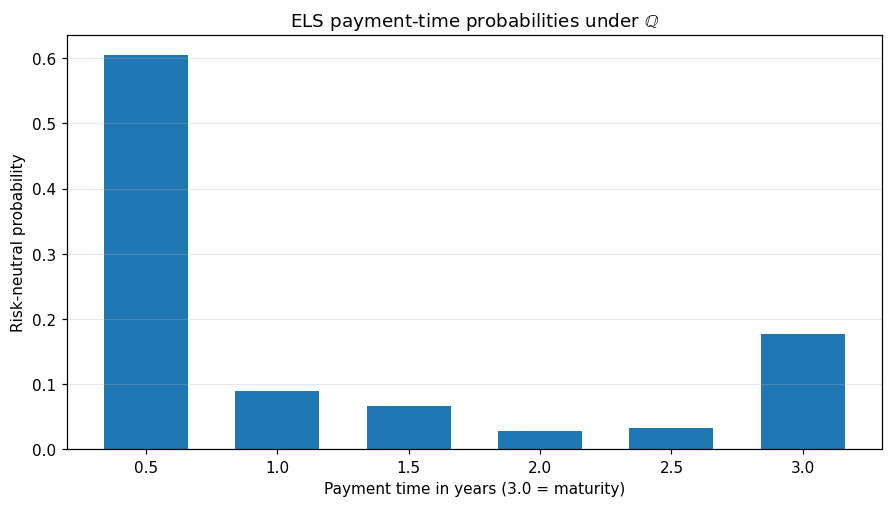

In [7]:
from pathlib import Path

figure_dir = Path("figures") / "section10"
figure_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8.0, 4.5), layout="constrained")
ax.bar(redemption_table["time"], redemption_table["probability"], width=0.32)
ax.set_title(r"ELS payment-time probabilities under $\mathbb{Q}$")
ax.set_xlabel("Payment time in years (3.0 = maturity)")
ax.set_ylabel("Risk-neutral probability")
ax.grid(True, axis="y", alpha=0.3)

figure_path = figure_dir / "els_early_redemption_probabilities.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

마지막 3.0년 막대는 **만기에 지급되는 전체 확률**입니다. 조기상환은 0.5–2.5년의 다섯 시점에만 해당합니다. 여섯 지급시점의 확률을 합하면 1이 되어야 합니다.

## 4. Delta, Gamma, Vega와 Cega

가격함수를 조금씩 다른 입력으로 재평가합니다. 예를 들어

$$\Delta_1\approx\frac{V(S_1+h,S_2)-V(S_1-h,S_2)}{2h},\qquad
\Gamma_1\approx\frac{V(S_1+h,S_2)-2V(S_1,S_2)+V(S_1-h,S_2)}{h^2}.$$

원본 `market`을 바꾸지 않도록 배열까지 복사합니다. 각 재평가에 같은 seed와 같은 난수 생성 순서를 쓰는 **common random numbers**를 적용합니다. 아래 함수 정의 후 본문과 같은 **10,000경로, 360단계**로 호출합니다.

**시장입력 사전을 안전하게 복사하는 함수**  
강의록 Listing 9 · `section10_els_pricing_hedging.tex` 575행

In [8]:
def copy_market(market):
    copied = {}

    for key, value in market.items():
        if key in {"spots", "volatilities", "dividend_yields"}:
            copied[key] = np.asarray(value, dtype=float).copy()
        else:
            copied[key] = value.copy() if isinstance(value, np.ndarray) else value

    return copied

**ELS Delta, Gamma, Vega와 Cega 계산**  
강의록 Listing 10 · `section10_els_pricing_hedging.tex` 588행

In [9]:
def stepdown_els_greeks(
    terms,
    market,
    n_paths,
    n_steps,
    seed,
    spot_bump=1.0,
    vol_bump=0.01,
    corr_bump=0.02,
):
    spot_bump = float(spot_bump)
    vol_bump = float(vol_bump)
    corr_bump = float(corr_bump)
    bumps = [spot_bump, vol_bump, corr_bump]
    if not np.isfinite(bumps).all() or min(bumps) <= 0.0:
        raise ValueError("bumps must be finite and positive")
    if np.any(np.asarray(market["spots"], dtype=float) <= spot_bump):
        raise ValueError("spot_bump must be smaller than both spots")
    if np.any(np.asarray(market["volatilities"], dtype=float) < vol_bump):
        raise ValueError("vol_bump must not produce negative volatility")
    if abs(float(market["correlation"])) + corr_bump >= 1.0:
        raise ValueError("correlation bumps must stay strictly inside (-1, 1)")

    base = price_stepdown_els(terms, market, n_paths, n_steps, seed)["price"]
    deltas = []
    gammas = []
    vegas = []

    for asset in range(2):
        up_market = copy_market(market)
        down_market = copy_market(market)
        up_market["spots"][asset] += spot_bump
        down_market["spots"][asset] -= spot_bump

        up = price_stepdown_els(
            terms, up_market, n_paths, n_steps, seed
        )["price"]
        down = price_stepdown_els(
            terms, down_market, n_paths, n_steps, seed
        )["price"]

        deltas.append((up - down) / (2.0 * spot_bump))
        gammas.append((up - 2.0 * base + down) / spot_bump**2)

        up_market = copy_market(market)
        down_market = copy_market(market)
        up_market["volatilities"][asset] += vol_bump
        down_market["volatilities"][asset] -= vol_bump

        up = price_stepdown_els(
            terms, up_market, n_paths, n_steps, seed
        )["price"]
        down = price_stepdown_els(
            terms, down_market, n_paths, n_steps, seed
        )["price"]
        vegas.append((up - down) / (2.0 * vol_bump))

    up_market = copy_market(market)
    down_market = copy_market(market)
    up_market["correlation"] += corr_bump
    down_market["correlation"] -= corr_bump

    up = price_stepdown_els(terms, up_market, n_paths, n_steps, seed)["price"]
    down = price_stepdown_els(terms, down_market, n_paths, n_steps, seed)["price"]
    cega = (up - down) / (2.0 * corr_bump)

    return {
        "price": base,
        "delta_1": deltas[0],
        "delta_2": deltas[1],
        "gamma_1": gammas[0],
        "gamma_2": gammas[1],
        "vega_1": vegas[0],
        "vega_2": vegas[1],
        "cega": cega,
    }

**ELS Greeks 계산 예시**  
강의록 Listing 11 · `section10_els_pricing_hedging.tex` 667행

In [10]:
greeks = stepdown_els_greeks(
    terms=terms,
    market=market,
    n_paths=10_000,
    n_steps=360,
    seed=2026,
)

print(pd.Series(greeks))

price      96.188849
delta_1     0.219568
delta_2     0.384104
gamma_1    -0.144510
gamma_2    -0.064083
vega_1    -36.018901
vega_2    -53.528489
cega        3.960153
dtype: float64


**강의록에 제시된 참고 출력 · Listing 12**  
아래 블록은 강의록의 원문입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에 저장되어 있습니다.

```text
price      96.188849
delta_1     0.219568
delta_2     0.384104
gamma_1    -0.144510
gamma_2    -0.064083
vega_1    -36.018901
vega_2    -53.528489
cega        3.960153
```

**결과 해석:** 이 표는 Monte Carlo 추정치이며 정확한 기준 Greeks가 아닙니다. 특히 Gamma는 시드·경로 수·bump에 따라 부호까지 달라질 수 있습니다. 이 결과 하나만으로 발행사의 long/short gamma를 확정하지 않습니다.

Vega와 Cega는 변동성 또는 상관계수가 **1.0** 변할 때의 민감도입니다. 1%p = 0.01 변화에 대한 일차 가격변화는 아래처럼 환산합니다.

In [11]:
pd.Series({
    "volatility_1 +1%p": 0.01 * greeks["vega_1"],
    "volatility_2 +1%p": 0.01 * greeks["vega_2"],
    "correlation +0.01": 0.01 * greeks["cega"],
}, name="일차 가격변화")

volatility_1 +1%p   -0.360189
volatility_2 +1%p   -0.535285
correlation +0.01    0.039602
Name: 일차 가격변화, dtype: float64

## 5. 현금계정을 유지하는 Delta hedge

발행사의 ELS 계약포지션은 $-V$이므로 기초자산을 $\Delta$만큼 보유합니다. 리밸런싱에서는 기존 현금에서 **실제로 거래한 주식의 대금만** 차감합니다. 매일 현금을 `가격 - 주식가치`로 새로 설정하면 자기금융 헤지가 아닙니다.

아래 함수는 한 번의 주식 거래를 처리합니다. 그다음 보충 예제로 거래 직전·직후의 포트폴리오 가치가 같은지 확인합니다. 이 보충 예제의 수치는 거래대금 계산을 설명하기 위한 값이며 ELS의 계산된 Delta가 아닙니다.

**한 기초자산의 Delta hedge 보유량 조정**  
강의록 Listing 13 · `section10_els_pricing_hedging.tex` 799행

In [12]:
def rebalance_delta_hedge(cash, current_shares, target_delta, spot):
    cash = float(cash)
    current_shares = float(current_shares)
    target_delta = float(target_delta)
    spot = float(spot)

    trade = target_delta - current_shares
    cash -= trade * spot
    return cash, target_delta, trade

In [13]:
cash_before, shares_before, new_delta, spot_now = 50.0, 0.40, 0.55, 100.0
cash_after, shares_after, trade = rebalance_delta_hedge(
    cash_before, shares_before, new_delta, spot_now
)
value_before = cash_before + shares_before * spot_now
value_after = cash_after + shares_after * spot_now
print(f"매수량: {trade:.2f}, 거래 후 현금: {cash_after:.2f}, 주식 수: {shares_after:.2f}")
print(f"거래 전/후 포트폴리오 가치: {value_before:.2f} / {value_after:.2f}")
assert np.isclose(value_before, value_after)

매수량: 0.15, 거래 후 현금: 35.00, 주식 수: 0.55
거래 전/후 포트폴리오 가치: 90.00 / 90.00


## 6. 강의록의 별도 1자산 FDM·일별 헤지 프로그램

강의록의 두 보조 그림은 **1자산 상품**입니다. 배당률 0, 변동성 25%, 연 252회 knock-in 관찰, 126시점 간격의 상환 관찰을 사용합니다. FDM은 $S_{\max}=250$, 공간구간 1,000개, 하루 사이 implicit Euler 4단계를 사용합니다. 주가 시나리오는 drift 1%, 변동성 25%, seed 24입니다.

이 부분에서는 첨부 원본의 `scripts/section10_figure_model.py` 함수를 그대로 가져와 셀로 나눴습니다. 가격은 $\mathbb{Q}$ 아래에서 계산하고, 모의 주가 시나리오는 별도의 drift를 사용합니다. 두 knock-in 상태의 가격을 각각 저장하고, 그날 관찰을 통과한 생존 계약을 재평가하여 헤지합니다.

원본 파일의 터미널 명령도 아래에 보관했습니다. 이어지는 Python 셀들은 계산을 직접 다시 수행하고, 노트북 안에 표와 그림을 표시합니다.

**터미널에서 실행하는 명령 · Listing 14**  
아래 블록은 강의록의 원문입니다. 노트북에서는 뒤의 Python 셀들로 같은 계산을 수행합니다.

```bash
python scripts/regenerate_section10_figures.py
```

In [14]:
from pathlib import Path
import json
import numpy as np
from scipy.sparse import diags
from scipy.sparse.linalg import splu

**입력 설정.** 본문 그림과 동일한 값입니다. `curve_day=121`은 첫 조기상환일 126일 직전의 상태별 곡선을 선택합니다.

In [15]:
DEFAULTS = {
    "reference": 100.0, "notional": 100.0, "maturity": 3.0,
    "rate": 0.03, "dividend_yield": 0.0, "volatility": 0.25,
    "coupon_rate": 0.08, "knock_in_level": 60.0,
    "observation_days": [126, 252, 378, 504, 630, 756],
    "autocall_levels": [90.0, 90.0, 85.0, 85.0, 80.0, 80.0],
    "days_per_year": 252, "s_max": 250.0, "n_space": 1000,
    "substeps_per_day": 4, "path_seed": 24, "physical_drift": 0.01,
    "curve_day": 121,
}

**두 상태의 FDM.** knock-in 미발생/발생 배열을 따로 계산합니다. 계약의 관찰일에만 상태를 전환하고 조기상환 조건을 적용합니다. 반환 배열은 그날 관찰 직후 생존한 계약의 가치입니다.

In [16]:
def solve_els_fdm(settings=None):
    """Return post-observation values for alive contracts at each daily close."""
    cfg = {**DEFAULTS, **(settings or {})}
    if cfg["dividend_yield"] != 0.0:
        raise ValueError("The associated hedge example assumes no dividends")
    n_space = cfg["n_space"]
    substeps = cfg["substeps_per_day"]
    if type(n_space) is not int or n_space < 10:
        raise ValueError("n_space must be an integer >= 10")
    if type(substeps) is not int or substeps < 1:
        raise ValueError("substeps_per_day must be a positive integer")
    n_days = int(round(cfg["maturity"] * cfg["days_per_year"]))
    if n_days != cfg["observation_days"][-1]:
        raise ValueError("Last observation must be the maturity")
    obs = dict(zip(cfg["observation_days"], cfg["autocall_levels"]))
    s = np.linspace(0.0, cfg["s_max"], num=n_space + 1)
    ds = s[1] - s[0]
    dt = 1.0 / (cfg["days_per_year"] * substeps)
    rate, sigma = cfg["rate"], cfg["volatility"]
    interior = s[1:-1]
    a = 0.5 * sigma**2 * interior**2 / ds**2 - rate * interior / (2.0 * ds)
    b = -sigma**2 * interior**2 / ds**2 - rate
    c = 0.5 * sigma**2 * interior**2 / ds**2 + rate * interior / (2.0 * ds)
    if np.min(a) < -1e-12 or np.min(c) < -1e-12:
        raise ValueError("This demonstration requires nonnegative off-diagonal stencil coefficients")
    matrix = diags((-dt*a[1:], 1.0-dt*b, -dt*c[:-1]), (-1,0,1), format="csc")
    lu = splu(matrix)
    final_coupon = cfg["notional"] * (1.0 + cfg["coupon_rate"] * cfg["maturity"])
    ki_values = np.where(s >= cfg["autocall_levels"][-1], final_coupon,
                         cfg["notional"] * s / cfg["reference"])
    no_values = np.full_like(s, final_coupon)
    hit = s <= cfg["knock_in_level"]
    no_values[hit] = ki_values[hit]  # final knock-in observation
    no_post = np.empty((n_days + 1, n_space + 1), dtype=float)
    ki_post = np.empty_like(no_post)
    no_post[-1], ki_post[-1] = no_values, ki_values
    for step in range(n_days*substeps - 1, -1, -1):
        t = step * dt
        # Boundary is evaluated after any event at t: the next event is strictly later.
        next_day = next(d for d in cfg["observation_days"] if d*substeps > step)
        pay_time = next_day / cfg["days_per_year"]
        upper = cfg["notional"] * (1.0 + cfg["coupon_rate"] * pay_time)
        upper *= np.exp(-rate * (pay_time - t))
        rhs = np.column_stack((no_values[1:-1], ki_values[1:-1]))
        rhs[-1, :] += dt * c[-1] * upper
        sol = lu.solve(rhs)
        no_values = np.r_[0.0, sol[:, 0], upper]
        ki_values = np.r_[0.0, sol[:, 1], upper]
        if step % substeps == 0:
            day = step // substeps
            no_post[day], ki_post[day] = no_values, ki_values
            # Backward event update: value just before today's observations.
            if day > 0:
                no_values[hit] = ki_values[hit]
            if day in obs:
                redeem = s >= obs[day]
                amount = cfg["notional"] * (1.0 + cfg["coupon_rate"] * t)
                no_values[redeem] = amount
                ki_values[redeem] = amount
    assert np.isfinite(no_post).all() and np.isfinite(ki_post).all()
    assert np.min(no_post) >= -1e-8 and np.min(ki_post) >= -1e-8
    assert np.min(no_post-ki_post) >= -1e-7
    return cfg, s, no_post, ki_post

**격자에서 Greeks 계산.** 각 상태 배열 안에서만 중심차분합니다. 두 상태를 이어 붙인 뒤 미분하지 않습니다.

In [17]:
def grid_greeks(values, ds):
    """Central differences within a single state, no mixing of state arrays."""
    delta = (values[..., 2:] - values[..., :-2]) / (2.0 * ds)
    gamma = (values[..., 2:] - 2.0*values[..., 1:-1] + values[..., :-2]) / ds**2
    return delta, gamma

**일별 주가 시나리오.** 본문과 같은 Euler 경로를 seed 24로 생성합니다.

In [18]:
def simulate_daily_path(cfg):
    rng = np.random.default_rng(cfg["path_seed"])
    n = int(cfg["maturity"] * cfg["days_per_year"])
    dt = 1.0/cfg["days_per_year"]
    path = np.empty(n+1, dtype=float)
    path[0] = cfg["reference"]
    for k in range(n):
        drift = cfg["physical_drift"] * path[k] * dt
        diffusion = cfg["volatility"] * path[k] * np.sqrt(dt) * rng.standard_normal()
        path[k+1] = path[k] + drift + diffusion
    if np.any(path <= 0.0):
        raise RuntimeError("Nonpositive Euler stock: change the example's time step")
    return path

**일별 자기금융 헤지.** 기존 현금에 이자를 반영한 뒤 목표 Delta에 필요한 거래대금만 차감합니다. 상환일에는 보유주식을 청산하고 ELS 현금흐름을 지급합니다.

In [19]:
def hedge_daily(cfg, stock_grid, no_post, ki_post):
    path = simulate_daily_path(cfg)
    inner = stock_grid[1:-1]
    ds = stock_grid[1]-stock_grid[0]
    delta0, _ = grid_greeks(no_post, ds)
    delta1, _ = grid_greeks(ki_post, ds)
    obs = dict(zip(cfg["observation_days"], cfg["autocall_levels"]))
    days_per_year = cfg["days_per_year"]
    price0 = float(np.interp(path[0], stock_grid, no_post[0]))
    shares = float(np.interp(path[0], inner, delta0[0]))
    cash = price0-shares*path[0]
    knocked_in = path[0] <= cfg["knock_in_level"]
    # day, spot, KI, claim value, target delta after close, shares held on arrival,
    # cash after close/settlement, shares after close, mark-to-market hedge error
    records = [[0, path[0], int(knocked_in), price0, shares, shares, cash, shares, 0.0]]
    residuals = []
    final_day = len(path)-1
    for day in range(1,len(path)):
        old_cash, old_shares = cash, shares
        cash *= np.exp(cfg["rate"]/days_per_year)
        spot = path[day]
        if not (inner[0] <= spot <= inner[-1]):
            raise ValueError("Hedge path is outside the Greek interpolation grid")
        knocked_in = knocked_in or spot <= cfg["knock_in_level"]
        redeemed = day in obs and spot >= obs[day]
        if redeemed or day == len(path)-1:
            amount = cfg["notional"] * (1.0+cfg["coupon_rate"]*day/days_per_year)
            if not redeemed and knocked_in:
                amount = cfg["notional"] * spot/cfg["reference"]
            pnl = cash+shares*spot-amount
            cash, shares = pnl, 0.0
            residuals.append(cash-(old_cash*np.exp(cfg["rate"]/days_per_year)+old_shares*spot-amount))
            records.append([day, spot, int(knocked_in), amount, 0.0, old_shares,cash,shares,pnl])
            final_day=day
            break
        values = ki_post if knocked_in else no_post
        deltas = delta1 if knocked_in else delta0
        value = float(np.interp(spot,stock_grid,values[day]))
        target = float(np.interp(spot,inner,deltas[day]))
        cash -= (target-shares)*spot
        shares = target
        residuals.append(cash-(old_cash*np.exp(cfg["rate"]/days_per_year)-(shares-old_shares)*spot))
        pnl = cash+shares*spot-value
        records.append([day,spot,int(knocked_in),value,target,old_shares,cash,shares,pnl])
    assert max(abs(x) for x in residuals) < 1e-10
    return np.asarray(records), {"initial_price":price0,"redemption_time":final_day/days_per_year,
        "final_pnl":float(records[-1][-1]),"max_self_financing_residual":max(abs(x) for x in residuals),
        "knock_in_occurred":bool(knocked_in)}

**계산과 기록 저장.** 상태별 곡선, 일별 거래기록, 입력값과 격자 점검표를 `_validation`에 저장합니다. 세 격자를 비교하지만 이것만으로 완전한 수렴 증명을 대신하지는 않습니다.

In [20]:
def calculate_and_save(output_root):
    root=Path(output_root);dest=root/'_validation';dest.mkdir(exist_ok=True)
    cfg,s,v0,v1=solve_els_fdm()
    rows,meta=hedge_daily(cfg,s,v0,v1)
    day=cfg['curve_day'];ds=s[1]-s[0];d0,g0=grid_greeks(v0[day],ds);d1,g1=grid_greeks(v1[day],ds)
    curves=np.column_stack((s[1:-1],v0[day,1:-1],v1[day,1:-1],d0,d1,g0,g1))
    np.savetxt(dest/'els_state_curves.csv',curves,delimiter=',',comments='',
        header='spot,no_knock_in_value,knocked_in_value,no_knock_in_delta,knocked_in_delta,no_knock_in_gamma,knocked_in_gamma')
    np.savetxt(dest/'els_hedge_trace.csv',rows,delimiter=',',comments='',
        header='day,spot,knocked_in,claim_value,target_delta,shares_before_close,cash_after_close,shares_after_close,hedging_error')
    coarse=[]
    for ns,sub in [(500,2),(1000,2),(1000,4)]:
        if (ns,sub)==(1000,4):p=meta['initial_price']
        else:
            _,ss,a,b=solve_els_fdm({'n_space':ns,'substeps_per_day':sub})
            p=float(np.interp(100.,ss,a[0]))
        coarse.append({'n_space':ns,'substeps_per_day':sub,'price':p})
    meta.update({'settings':cfg,'curve_time':day/cfg['days_per_year'],'grid_checks':coarse,
        'scope':'single-asset educational example; daily KI; no full convergence proof'})
    (dest/'els_figure_metadata.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2))
    return cfg,curves,rows,meta

In [21]:
cfg, state_curves, hedge_rows, figure_meta = calculate_and_save(Path("."))
print(f"1자산 초기 모형가격: {figure_meta['initial_price']:.6f}")
print(f"선택 경로의 상환시점: {figure_meta['redemption_time']:.2f}년")
print(f"선택 경로의 최종 자기금융 헤지손익: {figure_meta['final_pnl']:.6f}")
print(f"자기금융 항등식 최대 잔차: {figure_meta['max_self_financing_residual']:.3e}")
pd.DataFrame(figure_meta["grid_checks"])

1자산 초기 모형가격: 99.064585
선택 경로의 상환시점: 2.50년
선택 경로의 최종 자기금융 헤지손익: 0.271278
자기금융 항등식 최대 잔차: 0.000e+00


,n_space,substeps_per_day,price
0,500,2,99.089862
1,1000,2,99.068585
2,1000,4,99.064585


### 6.1 일별 경로, 주식 보유량과 헤지손익

이 그림은 **선택한 한 경로의 설명용 예시**입니다. 헤지손익의 분포를 추정한 결과는 아닙니다. 마지막 관찰일에는 최종 청산손익을 표시합니다.

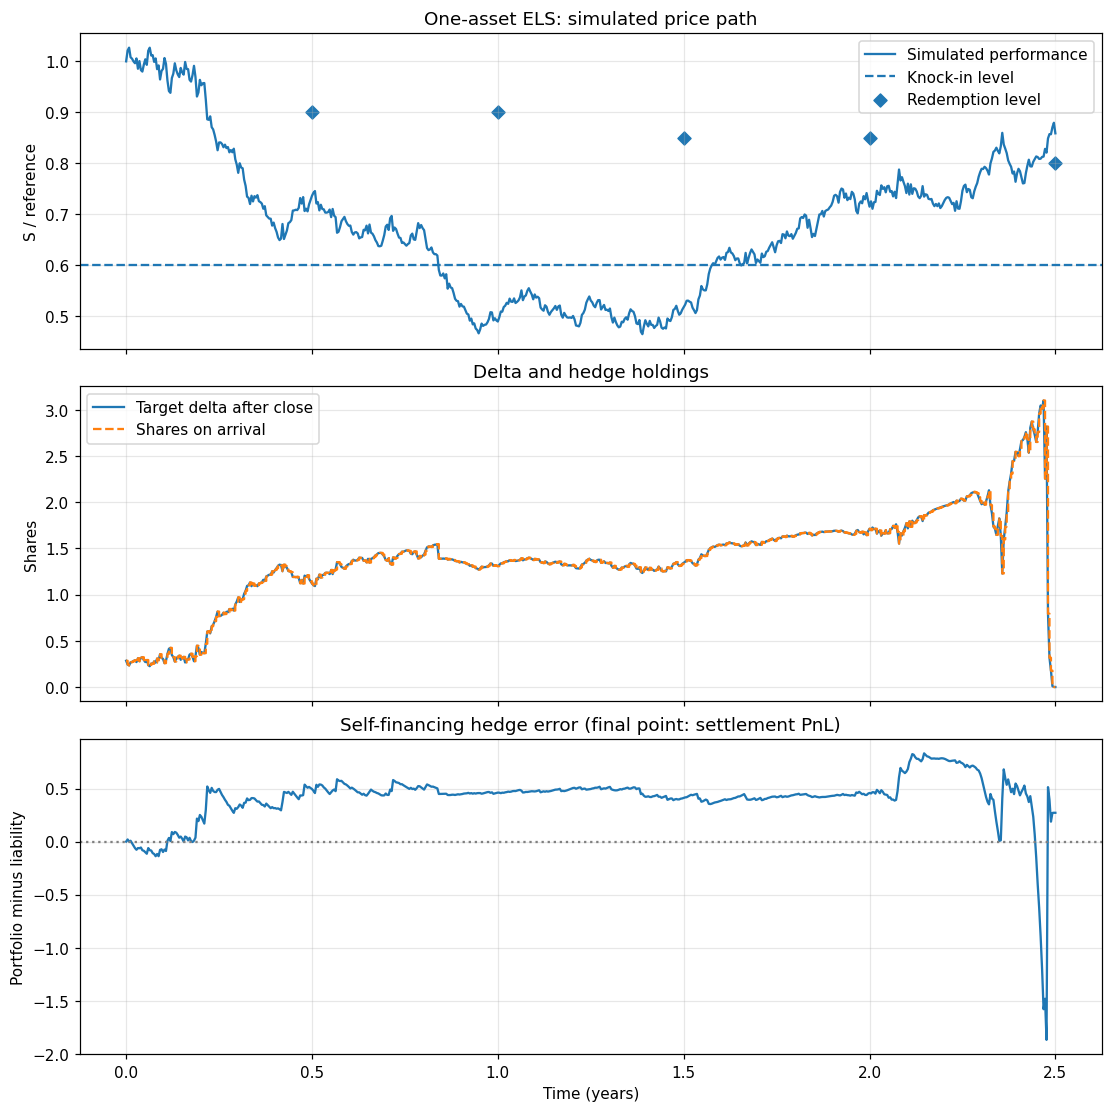

In [22]:
times = hedge_rows[:, 0] / cfg["days_per_year"]
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, layout="constrained")
axes[0].plot(times, hedge_rows[:, 1] / cfg["reference"], label="Simulated performance")
axes[0].axhline(cfg["knock_in_level"] / cfg["reference"], ls="--", label="Knock-in level")
obs_days = np.asarray(cfg["observation_days"])
obs_levels = np.asarray(cfg["autocall_levels"])
visible = obs_days <= hedge_rows[-1, 0]
axes[0].scatter(obs_days[visible] / cfg["days_per_year"], obs_levels[visible] / cfg["reference"], marker="D", label="Redemption level")
axes[0].set(title="One-asset ELS: simulated price path", ylabel="S / reference")
axes[0].legend()
axes[1].plot(times, hedge_rows[:, 4], label="Target delta after close")
axes[1].step(times, hedge_rows[:, 5], where="pre", ls="--", label="Shares on arrival")
axes[1].set(title="Delta and hedge holdings", ylabel="Shares")
axes[1].legend()
axes[2].plot(times, hedge_rows[:, 8])
axes[2].axhline(0.0, ls=":", color="gray")
axes[2].set(title="Self-financing hedge error (final point: settlement PnL)", xlabel="Time (years)", ylabel="Portfolio minus liability")
for ax in axes:
    ax.grid(alpha=0.3)
fig.savefig(figure_dir / "notebook_els_hedge.png", dpi=150)
plt.show()

In [23]:
hedge_table = pd.DataFrame(hedge_rows, columns=[
    "day", "spot", "knocked_in", "claim_value", "target_delta",
    "shares_before_close", "cash_after_close", "shares_after_close", "hedging_error",
])
hedge_table.tail()

,day,spot,knocked_in,claim_value,target_delta,shares_before_close,cash_after_close,shares_after_close,hedging_error
626,626.0,85.711863,1.0,119.581715,0.317334,0.792822,92.777674,0.317334,0.395219
627,627.0,85.678945,1.0,119.789630,0.177264,0.317334,104.789759,0.177264,0.187902
628,628.0,87.056843,1.0,119.964332,0.009965,0.177264,119.366747,0.009965,0.269928
629,629.0,87.938366,1.0,119.985636,0.000142,0.009965,120.244809,0.000142,0.271619
630,630.0,85.867098,1.0,120.000000,0.000000,0.000142,0.271278,0.000000,0.271278


### 6.2 상태별 가격, Delta와 Gamma

시점은 $t=121/252$년, 당일 knock-in 관찰 직후입니다. 미발생 상태는 $S>60$ 중 경계에 인접한 차분 stencil을 제외한 구간만 표시합니다. 두 상태의 배열을 각각 미분합니다.

투자자 가치의 Gamma가 양수이면 발행사의 계약포지션 $-V$는 그 구간에서 short gamma입니다. Gamma의 부호는 주가와 knock-in 상태에 따라 달라질 수 있습니다.

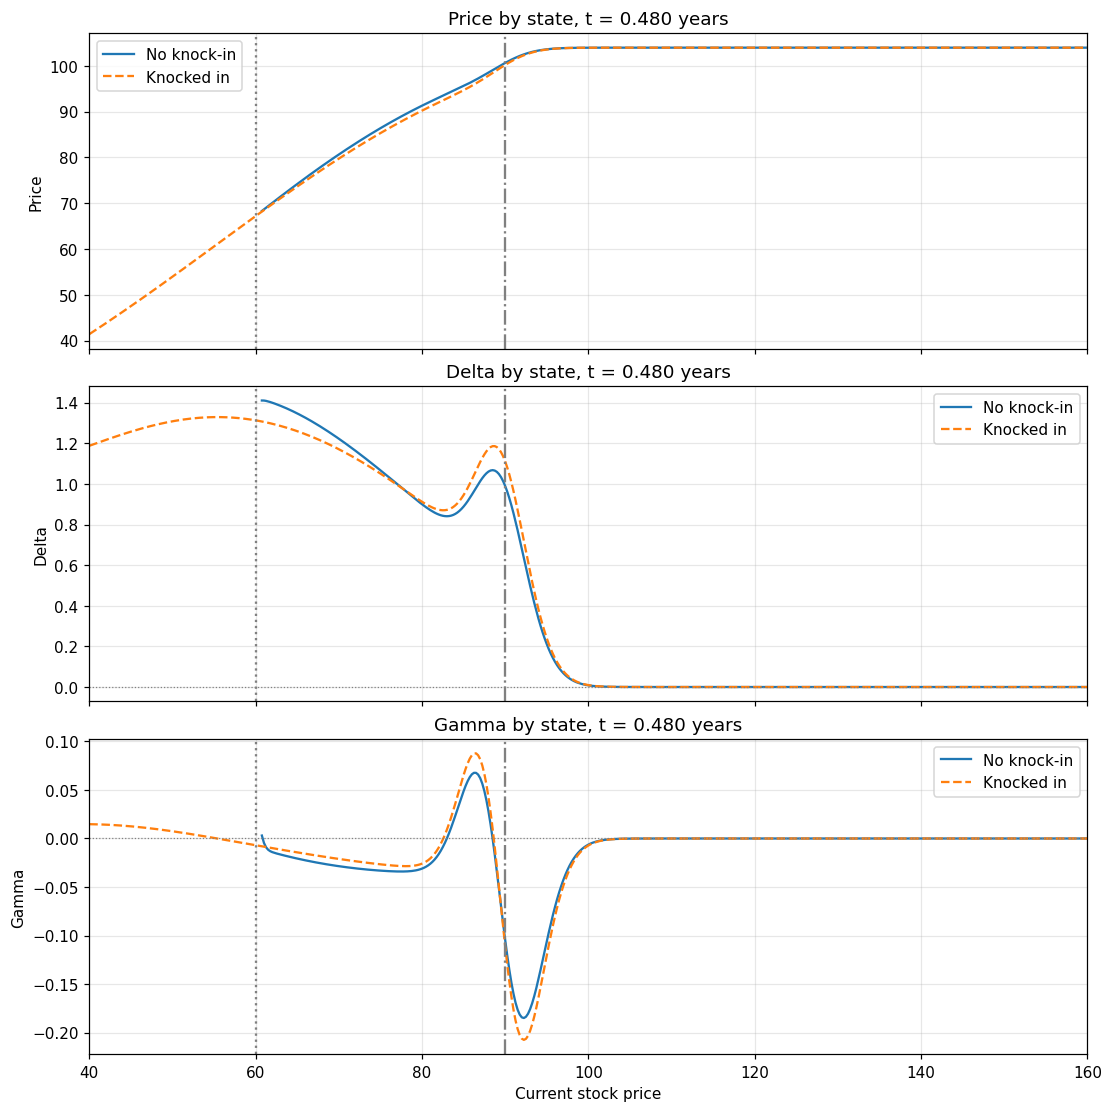

In [24]:
stock = state_curves[:, 0]
valid = (stock >= 40.0) & (stock <= 160.0)
no_ki = valid & (stock > cfg["knock_in_level"] + 2.0 * cfg["s_max"] / cfg["n_space"])
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, layout="constrained")
for ax, no_col, ki_col, label in zip(axes, [1, 3, 5], [2, 4, 6], ["Price", "Delta", "Gamma"]):
    ax.plot(stock[no_ki], state_curves[no_ki, no_col], label="No knock-in")
    ax.plot(stock[valid], state_curves[valid, ki_col], ls="--", label="Knocked in")
    ax.axvline(60.0, ls=":", color="gray")
    ax.axvline(90.0, ls="-.", color="gray")
    if label != "Price":
        ax.axhline(0.0, ls=":", color="gray", lw=0.8)
    ax.set(title=f"{label} by state, t = {figure_meta['curve_time']:.3f} years", ylabel=label, xlim=(40, 160))
    ax.grid(alpha=0.3)
    ax.legend()
axes[-1].set_xlabel("Current stock price")
fig.savefig(figure_dir / "notebook_els_state_curves.png", dpi=150)
plt.show()

## 7. 직접 해보기

먼저 위 결과를 확인한 뒤, 입력값을 **하나씩** 바꾸어 비교해 보세요. 아래는 강의록의 연습 주제이며 정답 코드를 숨겨 둔 셀은 없습니다.

1. `spot_bump`를 0.25, 0.50, 1.00, 2.00으로 바꾸어 Delta와 Gamma의 안정성을 비교하세요. 같은 seed를 쓴 경우와 bumped run에 서로 다른 seed를 쓴 경우를 구분하세요.
2. 쿠폰율, knock-in barrier, 상관계수를 하나씩 바꾸고 가격·상환확률·손실확률·평균상환기간을 비교하세요.
3. 첫 번째 자산의 현재주가를 70, 80, 90, 100, 110으로 바꾸고 Delta와 Gamma를 비교하세요. 기준가격 `reference_spots`는 100으로 유지합니다.
4. 1자산 MC와 FDM을 비교하려면 상품조건과 knock-in 관찰시점을 먼저 일치시키세요. 앞의 두 자산 MC 결과를 뒤의 1자산 FDM 결과와 직접 비교하지 않습니다.

**확인할 내용:** 각 경로의 지급시점으로 할인했는가, 지급시점 확률의 합이 1인가, MC Gamma가 seed와 bump에 민감한가, 현금계정이 실제 거래대금으로 갱신되는가, FDM에서 두 knock-in 상태를 따로 미분했는가.

CEV에서는 경로 생성 시 현재주가의 local volatility를 사용하며, 주가 bump 때 기준가격과 local-volatility reference level을 고정합니다. Heston에서는 분산과정과 추가 상관구조가 필요합니다. 이 장의 원문은 이 확장들의 개념을 설명하며 별도 완성 프로그램은 제시하지 않습니다.